

# Project : CarbonIQ – Business Sustainability Intelligence

Carbon footprint tracking for a multi-site business: Scope 1, 2 and 3 emissions, intensity, forecast, reduction target and an AI sustainability summary.

## What this notebook does
- Makes 24 months of made-up energy, fuel, travel and waste data for 5 facilities (or uses your carbon_data.csv)
- Converts activity data into tonnes of CO2e using emission factors
- Splits emissions into Scope 1, Scope 2 and Scope 3
- Calculates intensity per employee and per revenue
- Forecasts the next 12 months, after testing three simple methods on the last 6 months
- Tests reduction levers against a 30% reduction target
- Uses Groq AI to write a short sustainability summary

## How to run
1. Upload this file to Google Colab (or open it from Drive)
2. Runtime → Run all, or run each cell one by one
3. If a step fails, run the cell again, then restart the runtime once and run again

## Step 1: Install libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn openai

## Step 2: Connect to Groq (the AI part)
Paste your Groq API key when it asks. The key is hidden while you type.

In [2]:
import time
from getpass import getpass
from openai import OpenAI

GROQ_KEY = getpass("Paste your Groq API key: ")
client = OpenAI(api_key=GROQ_KEY, base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"

def ask_llm(question, system="You are a helpful analyst.", model=MODEL):
    for tries in range(3):
        try:
            r = client.chat.completions.create(
                model=model,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
                max_tokens=1500,
                temperature=0.3,
            )
            return r.choices[0].message.content
        except Exception as e:
            print("llm error, trying again:", str(e)[:100])
            time.sleep(5)
    return "LLM not available right now."

print(ask_llm("Say hi in five words."))

Paste your Groq API key: ··········
Hello, great to see you!


## Step 3: Load the data and set emission factors
The emission factors are rough public-style values (assumptions). Change them if you have your own.

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
np.random.seed(21)
sns.set_style("whitegrid")

factors = {"electricity_kwh": 0.71, "diesel_l": 2.68, "gas_m3": 2.0, "travel_km": 0.15, "waste_kg": 0.5}

def make_data():
    sites = {"Pune Plant": 1.6, "Mumbai Office": 0.7, "Delhi Warehouse": 1.0, "Chennai Plant": 1.4, "Bengaluru Office": 0.6}
    rows = []
    months = pd.date_range("2024-10-01", periods=24, freq="MS")
    for site, size in sites.items():
        for i, m in enumerate(months):
            summer = 1.2 if m.month in [4, 5, 6] else 1.0
            trend = 1 - 0.004 * i
            rows.append({
                "facility": site, "month": m,
                "electricity_kwh": 90000 * size * summer * trend * np.random.normal(1, 0.05),
                "diesel_l": 6000 * size * trend * np.random.normal(1, 0.1),
                "gas_m3": 3500 * size * np.random.normal(1, 0.1),
                "travel_km": 40000 * (0.5 + size / 2) * np.random.normal(1, 0.2),
                "waste_kg": 9000 * size * np.random.normal(1, 0.1),
                "employees": int(150 * size),
                "revenue": 5000000 * size * np.random.normal(1, 0.08),
            })
    return pd.DataFrame(rows)

if os.path.exists("carbon_data.csv"):
    data = pd.read_csv("carbon_data.csv", parse_dates=["month"])
    print("Using your carbon_data.csv")
else:
    data = make_data()
    print("Using sample data")

print(data.shape)
data.head()

Using sample data
(120, 9)


,facility,month,electricity_kwh,diesel_l,gas_m3,travel_km,waste_kg,employees,revenue
0,Pune Plant,2024-10-01,143625.857404,9493.251792,6183.406207,38929.911342,15473.358261,240,6.904926e+06
1,Pune Plant,2024-11-01,141947.705346,9337.312314,6231.760665,51868.690103,13516.991587,240,8.879161e+06
2,Pune Plant,2024-12-01,154354.349093,8866.834133,5987.477278,47339.597733,14633.773152,240,8.164627e+06
3,Pune Plant,2025-01-01,133198.917199,9545.506926,5005.360294,41710.568707,13740.878555,240,6.730124e+06
4,Pune Plant,2025-02-01,131235.702854,9665.370348,5960.729194,60862.076031,13731.813045,240,8.446193e+06


## Step 4: Calculate emissions (tonnes CO2e) and scopes

Total tonnes CO2e: 12284.6
scope1    23.1 %
scope2    66.2 %
scope3    10.7 %
dtype: object
Note: Scope 3 here covers only business travel and waste, so the real Scope 3 would be larger.


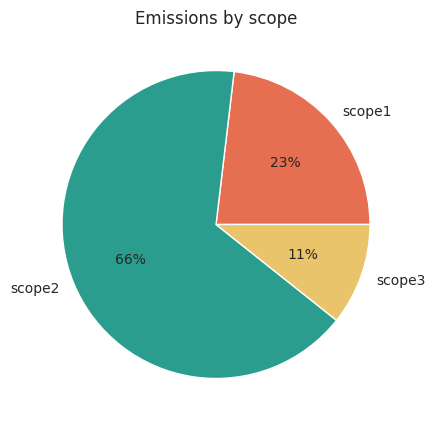

In [4]:
data["scope1"] = (data["diesel_l"] * factors["diesel_l"] + data["gas_m3"] * factors["gas_m3"]) / 1000
data["scope2"] = data["electricity_kwh"] * factors["electricity_kwh"] / 1000
data["scope3"] = (data["travel_km"] * factors["travel_km"] + data["waste_kg"] * factors["waste_kg"]) / 1000
data["total"] = data["scope1"] + data["scope2"] + data["scope3"]
data["per_employee"] = data["total"] / data["employees"]
data["per_million_revenue"] = data["total"] / (data["revenue"] / 1000000)

total_by_scope = data[["scope1", "scope2", "scope3"]].sum()
print("Total tonnes CO2e:", round(data["total"].sum(), 1))
print((total_by_scope / total_by_scope.sum() * 100).round(1).astype(str) + " %")
print("Note: Scope 3 here covers only business travel and waste, so the real Scope 3 would be larger.")

total_by_scope.plot(kind="pie", autopct="%1.0f%%", figsize=(5, 5), colors=["#e76f51", "#2a9d8f", "#e9c46a"])
plt.ylabel("")
plt.title("Emissions by scope")
plt.show()

## Step 5: Facilities and trend

                    total  per_employee  per_million_revenue
facility                                                    
Pune Plant        3647.60          0.63                19.03
Chennai Plant     3230.96          0.64                19.51
Delhi Warehouse   2342.89          0.65                19.61
Mumbai Office     1661.15          0.66                20.37
Bengaluru Office  1402.04          0.65                20.38

Emissions per employee differ by only 4.8 % between the best and worst facility
That is a very small gap, so no facility is clearly better or worse on this measure.


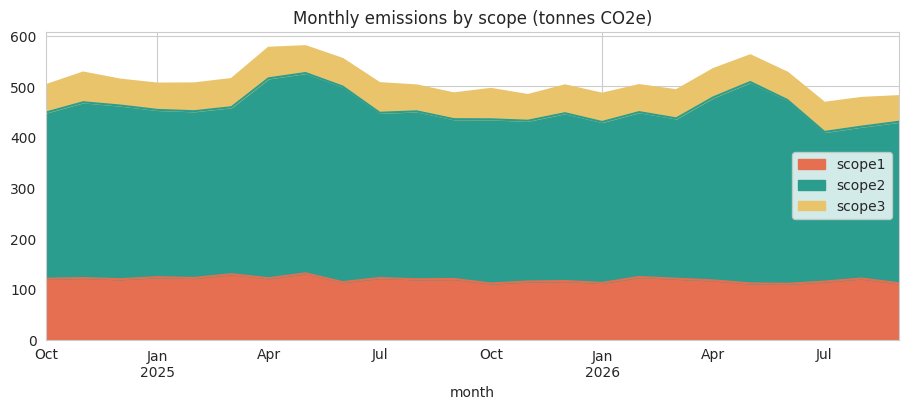

Year 1 total: 6274.8
Year 2 total: 6009.9
Change: -4.2 %


In [5]:
fac = data.groupby("facility").agg(total=("total", "sum"), per_employee=("per_employee", "mean"),
                                    per_million_revenue=("per_million_revenue", "mean")).sort_values("total", ascending=False).round(2)
print(fac)
intensity_spread = (fac["per_employee"].max() / fac["per_employee"].min() - 1) * 100
print("\nEmissions per employee differ by only", round(intensity_spread, 1), "% between the best and worst facility")
if intensity_spread < 10:
    print("That is a very small gap, so no facility is clearly better or worse on this measure.")

monthly = data.groupby("month")[["scope1", "scope2", "scope3"]].sum()
monthly.plot(kind="area", figsize=(11, 4), color=["#e76f51", "#2a9d8f", "#e9c46a"])
plt.title("Monthly emissions by scope (tonnes CO2e)")
plt.show()

first_year = data[data["month"] < data["month"].min() + pd.DateOffset(years=1)]["total"].sum()
second_year = data[data["month"] >= data["month"].min() + pd.DateOffset(years=1)]["total"].sum()
print("Year 1 total:", round(first_year, 1))
print("Year 2 total:", round(second_year, 1))
print("Change:", round((second_year - first_year) / first_year * 100, 1), "%")

## Step 6: Forecast the next 12 months (and test the forecast first)
We have only 24 months, so a fancy model can easily fool us. Three simple methods are tested on the last 6 months, and the best one is used for the forecast:
1. **Same month last year** (seasonal naive)
2. **Straight trend line**
3. **Trend + month effects**
MAPE is the average % error, lower is better.

Error on the last 6 months (MAPE %):
   same month last year -> 5.14
   straight trend line -> 5.6
   trend + month effects -> 2.45
Best method: trend + month effects

Next 12 months forecast total: 5745.0 tonnes (method: trend + month effects)


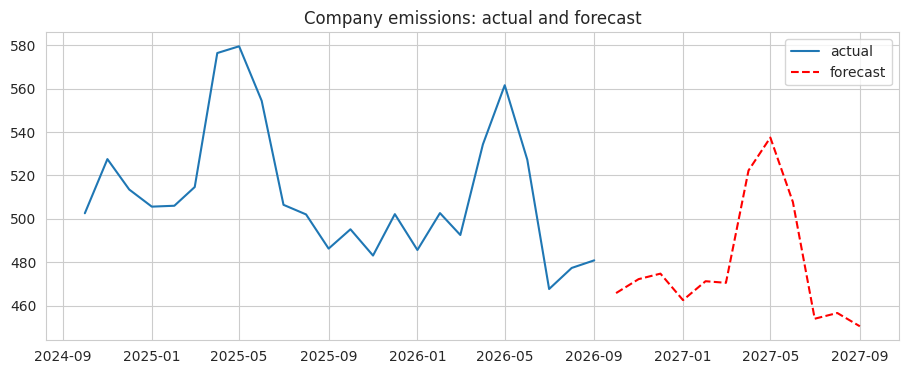

In [6]:
from sklearn.linear_model import LinearRegression

company = data.groupby("month")["total"].sum().reset_index()
company["t"] = np.arange(len(company))
company["month_num"] = company["month"].dt.month

def mape(actual, pred):
    return float(np.mean(np.abs((actual - pred) / actual)) * 100)

def season_matrix(frame, columns=None):
    X = pd.get_dummies(frame[["t", "month_num"]], columns=["month_num"])
    if columns is not None:
        X = X.reindex(columns=columns, fill_value=0)
    return X

train = company.iloc[:18]
test = company.iloc[18:]
actual = test["total"].values

pred_naive = company["total"].iloc[6:12].values
lr_trend = LinearRegression().fit(train[["t"]], train["total"])
pred_trend = lr_trend.predict(test[["t"]])
Xtr = season_matrix(train)
lr_season = LinearRegression().fit(Xtr, train["total"])
pred_season = lr_season.predict(season_matrix(test, Xtr.columns))

scores = {"same month last year": mape(actual, pred_naive), "straight trend line": mape(actual, pred_trend), "trend + month effects": mape(actual, pred_season)}
print("Error on the last 6 months (MAPE %):")
for k, v in scores.items():
    print("  ", k, "->", round(v, 2))
best_method = min(scores, key=scores.get)
print("Best method:", best_method)

future_months = pd.date_range(company["month"].max() + pd.DateOffset(months=1), periods=12, freq="MS")
future = pd.DataFrame({"month": future_months, "t": np.arange(len(company), len(company) + 12)})
future["month_num"] = future["month"].dt.month
if best_method == "same month last year":
    future["forecast"] = company["total"].iloc[12:24].values
elif best_method == "straight trend line":
    future["forecast"] = LinearRegression().fit(company[["t"]], company["total"]).predict(future[["t"]])
else:
    Xall = season_matrix(company)
    future["forecast"] = LinearRegression().fit(Xall, company["total"]).predict(season_matrix(future, Xall.columns))

print("\nNext 12 months forecast total:", round(future["forecast"].sum(), 1), "tonnes (method:", best_method + ")")
plt.figure(figsize=(11, 4))
plt.plot(company["month"], company["total"], label="actual")
plt.plot(future["month"], future["forecast"], "r--", label="forecast")
plt.legend()
plt.title("Company emissions: actual and forecast")
plt.show()

## Step 7: Reduction target and levers
Target: cut the next 12 months by 30% compared with the last 12 months.

Baseline (last 12 months): 6009.9
Target (-30%): 4206.9
                                     lever  saving  saving_pct_of_baseline  \
0        Solar + LED (cut electricity 25%)   992.7                    16.5   
1  Switch to EV/CNG fleet (cut diesel 30%)   283.3                     4.7   
2        Virtual meetings (cut travel 40%)   149.6                     2.5   
3          Waste recycling (cut waste 35%)    99.6                     1.7   
4             Gas efficiency (cut gas 15%)    65.4                     1.1   

   cumulative_pct  
0            16.5  
1            21.2  
2            23.7  
3            25.4  
4            26.5  

All levers together cut: 26.5 % (target is 30%)
Gap left: 3.5 % - needs more levers


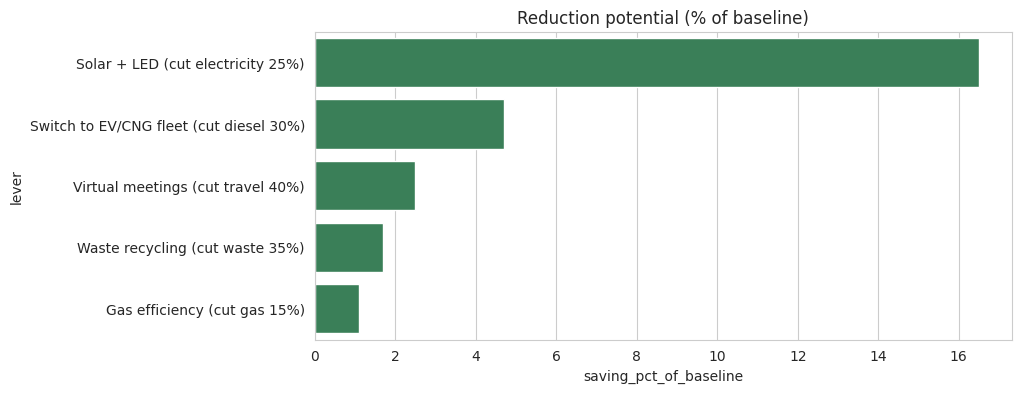

In [7]:
last12 = data[data["month"] > data["month"].max() - pd.DateOffset(months=12)]
baseline_total = last12["total"].sum()
target_total = baseline_total * 0.7
print("Baseline (last 12 months):", round(baseline_total, 1))
print("Target (-30%):", round(target_total, 1))

s1 = last12["scope1"].sum()
s2 = last12["scope2"].sum()
travel_part = (last12["travel_km"].sum() * factors["travel_km"]) / 1000
diesel_part = (last12["diesel_l"].sum() * factors["diesel_l"]) / 1000
waste_part = (last12["waste_kg"].sum() * factors["waste_kg"]) / 1000

levers = pd.DataFrame([
    {"lever": "Solar + LED (cut electricity 25%)", "saving": s2 * 0.25},
    {"lever": "Switch to EV/CNG fleet (cut diesel 30%)", "saving": diesel_part * 0.30},
    {"lever": "Virtual meetings (cut travel 40%)", "saving": travel_part * 0.40},
    {"lever": "Waste recycling (cut waste 35%)", "saving": waste_part * 0.35},
    {"lever": "Gas efficiency (cut gas 15%)", "saving": (s1 - diesel_part) * 0.15},
]).sort_values("saving", ascending=False)
levers["saving_pct_of_baseline"] = (levers["saving"] / baseline_total * 100).round(1)
levers["cumulative_pct"] = levers["saving_pct_of_baseline"].cumsum()
print(levers.round(1))

achieved = levers["saving"].sum() / baseline_total * 100
print("\nAll levers together cut:", round(achieved, 1), "% (target is 30%)")
if achieved >= 30:
    print("Target reached")
else:
    print("Gap left:", round(30 - achieved, 1), "% - needs more levers")

plt.figure(figsize=(9, 4))
sns.barplot(data=levers, y="lever", x="saving_pct_of_baseline", color="seagreen")
plt.title("Reduction potential (% of baseline)")
plt.show()

## Step 8: AI sustainability summary (Groq)
The summary only uses the last 12 months as the current footprint, and the AI is told not to claim that any action is already happening.

In [8]:
last12_scope = last12[["scope1", "scope2", "scope3"]].sum()
last12_share = (last12_scope / last12_scope.sum() * 100).round(1).to_dict()
text = f"""
Current footprint (last 12 months): {baseline_total:.0f} tonnes CO2e
Scope split of the last 12 months (%): {last12_share}
Scope 3 here only covers business travel and waste, so real Scope 3 is larger and unknown.
Highest emitting facility (all 24 months): {fac.index[0]} ({fac.iloc[0]['total']:.0f} t)
Facility intensity per employee differs by only {intensity_spread:.1f}% between best and worst facility
Year 1 vs Year 2 change: {(second_year - first_year) / first_year * 100:.1f}%
Forecast next 12 months: {future['forecast'].sum():.0f} t (method: {best_method}, test error {scores[best_method]:.1f}%)
Target: cut 30% from the baseline, which means {target_total:.0f} t
Possible levers with ASSUMED reduction percentages: {levers[['lever', 'saving_pct_of_baseline']].to_dict('records')}
Combined lever reduction if all assumptions hold: {achieved:.1f}% (target 30%)
"""
summary = ask_llm("Write a short sustainability summary for management (one paragraph on where we are, one on whether the levers reach the 30% target, 3 next steps). Use only these numbers. Do not say any action is already being deployed, because these are only planned scenarios. Say that the lever percentages are assumptions, that Scope 3 is partial, and that the data is made up.\n" + text,
                  system="You are a sustainability analyst. Do not invent numbers or claims.")
print(summary)

**Where we are** – Over the past 12 months the company emitted 6 010 t CO₂e, with the bulk coming from Scope 2 (66.1 %) and a smaller share from Scope 1 (23.0 %). Scope 3 is only partially captured (11.0 %) because it only includes business travel and waste, so the true Scope 3 figure is larger and unknown. The Pune Plant is the dominant source, accounting for 3 648 t (≈ 60 % of total) across the last 24 months, while facility‑per‑employee intensity varies by just 4.8 % between the best and worst sites. Year‑on‑year emissions fell 4.2 % and a trend‑plus‑month‑effects forecast predicts 5 745 t CO₂e for the next 12 months (test error ± 2.4 %). To meet the 30 % reduction target (4207 t CO₂e) we must close a gap of roughly 1 538 t.

**Do the planned levers get us to the target?** – The five proposed levers are based on assumed reduction percentages (Solar + LED – 25 % electricity, EV/CNG fleet – 30 % diesel, virtual meetings – 40 % travel, waste recycling – 35 % waste, gas efficiency – 15 

## Step 9: Key insights and export

In [9]:
print("KEY INSIGHTS (calculated from this run)")
print("1. Biggest scope:", total_by_scope.idxmax(), "-", round(total_by_scope.max() / total_by_scope.sum() * 100, 1), "% of all emissions (it depends on the assumed electricity factor)")
print("2. Scope 3 is partial (travel and waste only), so do not read its share as the real Scope 3 share")
print("3. Highest emitting facility:", fac.index[0], "| intensity per employee differs by only", round(intensity_spread, 1), "% across facilities")
print("4. Emissions changed", round((second_year - first_year) / first_year * 100, 1), "% from year 1 to year 2")
print("5. Forecast method chosen:", best_method, "with", round(scores[best_method], 1), "% error on the last 6 months")
print("6. Best single lever:", levers.iloc[0]["lever"], "(", levers.iloc[0]["saving_pct_of_baseline"], "% of baseline, based on an assumed reduction)")
print("7. All levers together:", round(achieved, 1), "% vs the 30% target. Gap:", round(max(0, 30 - achieved), 1), "points")
print("8. Data is made up unless you upload carbon_data.csv")

data.to_csv("carboniq_emissions.csv", index=False)
levers.to_csv("carboniq_levers.csv", index=False)
future.to_csv("carboniq_forecast.csv", index=False)
print("\nSaved carboniq_emissions.csv, carboniq_levers.csv and carboniq_forecast.csv")

KEY INSIGHTS (calculated from this run)
1. Biggest scope: scope2 - 66.2 % of all emissions (it depends on the assumed electricity factor)
2. Scope 3 is partial (travel and waste only), so do not read its share as the real Scope 3 share
3. Highest emitting facility: Pune Plant | intensity per employee differs by only 4.8 % across facilities
4. Emissions changed -4.2 % from year 1 to year 2
5. Forecast method chosen: trend + month effects with 2.4 % error on the last 6 months
6. Best single lever: Solar + LED (cut electricity 25%) ( 16.5 % of baseline, based on an assumed reduction)
7. All levers together: 26.5 % vs the 30% target. Gap: 3.5 points
8. Data is made up unless you upload carbon_data.csv

Saved carboniq_emissions.csv, carboniq_levers.csv and carboniq_forecast.csv



Built by **Akshat Kesharwani** | [GitHub](https://github.com/akshatkesharwani-info) | [Portfolio](https://akshatkesharwani-info.github.io/)